# Підготовка українського корпусу для Word2Vec

Беремо українську Вікіпедію, чистимо текст і збираємо корпус із 300 000 речень.

Пайплайн:

1. нижній регістр
2. розбиття на речення (`.`, `!`, `?`)
3. очистка (без цифр і зайвих символів, апострофи та дефіси всередині слів лишаємо)
4. розбиття на слова
5. фільтри: слова від 3 символів, речення від 5 слів, ціль — 300 000 речень

In [ ]:
%pip install -q datasets matplotlib

## Завантаження Вікіпедії

Беремо `wikimedia/wikipedia` (українська, `uk`) через `datasets` у режимі **streaming** — так не треба качати весь дамп, статті читаються по одній, і ми зупиняємось, коли назбирали 300 000 речень.

In [4]:
!pip install datasets

   ---------------------------------------- 0.0/604.4 kB ? eta -:--:--
   ---------------------------------------- 604.4/604.4 kB 5.4 MB/s  0:00:00
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ---------------------------------------- 857.0/857.0 kB 10.5 MB/s  0:00:00
   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   ------------------------------------- -- 3.7/3.9 MB 16.8 MB/s eta 0:00:01
   ---------------------------------------- 3.9/3.9 MB 14.3 MB/s  0:00:00
   ---------------------------------------- 0.0/29.0 MB ? eta -:--:--
   ----- ---------------------------------- 4.2/29.0 MB 20.4 MB/s eta 0:00:02
   --------- ------------------------------ 6.6/29.0 MB 16.7 MB/s eta 0:00:02
   ------------- -------------------------- 9.7/29.0 MB 15.1 MB/s eta 0:00:02
   ----------------- ---------------------- 12.6/29.0 MB 14.7 MB/s eta 0:00:02
   ------------------- -------------------- 14.2/29.0 MB 13.6 MB/s eta 0:00:02
   ------------------

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
geoclip 1.2.3 requires huggingface-hub<2,>=0.20, but you have huggingface-hub 2.4.0 which is incompatible.
label-studio 1.22.0 requires pyarrow<23.0.0,>=22.0.0, but you have pyarrow 26.0.1 which is incompatible.
onix 0.1.0 requires rich==7.0.0, but you have rich 15.0.0 which is incompatible.
tokenizers 0.22.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.4.0 which is incompatible.
transformers 5.6.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.4.0 which is incompatible.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
from datasets import load_dataset

wiki = load_dataset(
    "wikimedia/wikipedia",
    "20231101.uk",
    split="train",
    streaming=True
)

# дивимось на першу статтю
first = next(iter(wiki))
print(first["title"])
print(first["text"][:500])

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

C:\Users\intit\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\intit\.cache\huggingface\hub\datasets--wikimedia--wikipedia. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Географія
Геогра́фія, або заст. земле́пис (від  — опис Землі; де  — Земля і  — писати, описувати) — система наук, що вивчає географічну оболонку Землі (епігеосферу), її просторову природну і соціально-економічну різноманітність, господарство і населення планети, окремих її регіонів та країн, а також зв'язки між природним середовищем і діяльністю людини. В сучасному розумінні поняття «географія» заміщено поняттям «географічні науки».

Поняття 
Уперше термін «географія» був запропонований давньогрецьким гео


## Функції обробки

- **Крок 1** — `text.lower()`
- **Крок 2** — спочатку ріжемо по переносах рядків (щоб заголовки типу `== Історія ==` не липли до речень), потім по `.`, `!`, `?` разом із пробілом після них
- **Крок 3** — усе, що не є українською літерою, апострофом, дефісом або пробілом, замінюємо пробілом. Різні види апострофа (`’`, `ʼ`, `` ` ``) приводимо до `'`
- **Крок 4** — слова беремо регуляркою: літери, а `'` та `-` дозволені лише **всередині** слова (тому дефіс на початку/в кінці або `--` відпадають)
- **Крок 5** — фільтри по довжині слова і кількості слів у реченні

In [6]:
import re

UA_LETTERS = "а-щьюяєіїґ"

# слово: літери, а ' або - тільки між літерами (дір-ка, м'яч, будь-який)
WORD_RE = re.compile(rf"[{UA_LETTERS}]+(?:['\-][{UA_LETTERS}]+)*")
SENT_SPLIT_RE = re.compile(r"(?<=[.!?])\s+")
BAD_CHARS_RE = re.compile(rf"[^{UA_LETTERS}'\-\s]")

MIN_WORD_LEN = 3
MIN_SENT_WORDS = 5


def split_sentences(text):
    """Крок 2: розбиваємо текст статті на речення по . ! ?"""
    sentences = []
    for line in text.split("\n"):
        line = line.strip()
        if not line:
            continue
        sentences.extend(SENT_SPLIT_RE.split(line))
    return sentences


def clean_sentence(sentence):
    """Кроки 1 і 3: нижній регістр + прибираємо цифри, пунктуацію та інше"""
    sentence = sentence.lower()
    sentence = sentence.replace("’", "'").replace("ʼ", "'").replace("`", "'").replace("‐", "-").replace("–", " ").replace("—", " ")
    sentence = BAD_CHARS_RE.sub(" ", sentence)
    return sentence


def tokenize(sentence):
    """Крок 4: список слів"""
    return WORD_RE.findall(sentence)


def process_sentence(sentence):
    """Повний ланцюжок для одного речення. Повертає список слів або None."""
    words = tokenize(clean_sentence(sentence))
    words = [w for w in words if len(w) >= MIN_WORD_LEN]   # слова коротші за 3 символи геть
    if len(words) < MIN_SENT_WORDS:                        # речення з <5 слів геть
        return None
    return words


# швидка перевірка на прикладі
test = "Київ — столиця України, місто з населенням 2 967 360 осіб (2022). Це м'яке слово! А це вже 123 і ще якась-то хрінь??"
for s in split_sentences(test):
    print(s, "->", process_sentence(s))

Київ — столиця України, місто з населенням 2 967 360 осіб (2022). -> ['київ', 'столиця', 'україни', 'місто', 'населенням', 'осіб']
Це м'яке слово! -> None
А це вже 123 і ще якась-то хрінь?? -> None


## Збираємо корпус на 300 000 речень

In [7]:
TARGET = 300_000

sentences = []
articles_read = 0

for article in wiki:
    articles_read += 1

    for raw_sentence in split_sentences(article["text"]):
        words = process_sentence(raw_sentence)
        if words is not None:
            sentences.append(words)

        if len(sentences) >= TARGET:
            break

    if len(sentences) >= TARGET:
        break

    if articles_read % 5000 == 0:
        print(f"статей: {articles_read}, речень: {len(sentences)}")

print()
print("Прочитано статей:", articles_read)
print("Речень у корпусі:", len(sentences))

статей: 5000, речень: 256921

Прочитано статей: 6527
Речень у корпусі: 300000


## 5 прикладів очищених речень

In [8]:
for i, sentence in enumerate(sentences[:5], start=1):
    print(f"{i}. {sentence}")
    print()

1. ['земле', 'пис', 'від', 'опис', 'землі', 'земля', 'писати', 'описувати', 'система', 'наук', 'вивчає', 'географічну', 'оболонку', 'землі', 'епігеосферу', 'просторову', 'природну', 'соціально-економічну', 'різноманітність', 'господарство', 'населення', 'планети', 'окремих', 'регіонів', 'країн', 'також', "зв'язки", 'між', 'природним', 'середовищем', 'діяльністю', 'людини']

2. ['сучасному', 'розумінні', 'поняття', 'географія', 'заміщено', 'поняттям', 'географічні', 'науки']

3. ['уперше', 'термін', 'географія', 'був', 'запропонований', 'давньогрецьким', 'географом', 'ератосфеном']

4. ['основне', 'завдання', 'сучасної', 'географії', 'полягає', 'вивченні', 'законів', 'закономірностей', 'розміщення', 'взаємодії', 'компонентів', 'географічного', 'середовища', 'їхніх', 'поєднань', 'різних', 'рівнях']

5. ['складність', "об'єкта", 'дослідження', 'широта', 'предметної', 'області', 'зумовили', 'диференціацію', 'єдиної', 'географії', 'низку', 'спеціалізованих', 'галузевих', 'наукових', 'дисцип

## Додатково: аналіз корпусу

In [9]:
from collections import Counter

word_counter = Counter(word for sentence in sentences for word in sentence)

total_sentences = len(sentences)
total_words = sum(word_counter.values())
unique_words = len(word_counter)

print("Загальна кількість речень:", total_sentences)
print("Загальна кількість слів:", total_words)
print("Унікальних слів:", unique_words)
print()

top20 = word_counter.most_common(20)
print("20 найчастіших слів:")
for rank, (word, count) in enumerate(top20, start=1):
    print(f"{rank:2d}. {word:15s} {count}")

Загальна кількість речень: 300000
Загальна кількість слів: 3414846
Унікальних слів: 289783

20 найчастіших слів:
 1. року            24963
 2. від             16558
 3. його            12934
 4. для             12742
 5. україни         11663
 6. про             11546
 7. під             9709
 8. також           9496
 9. було            8907
10. році            8729
11. був             7679
12. він             7440
13. після           7307
14. району          7161
15. які             6977
16. або             6633
17. час             6018
18. території       5899
19. але             5876
20. між             5742


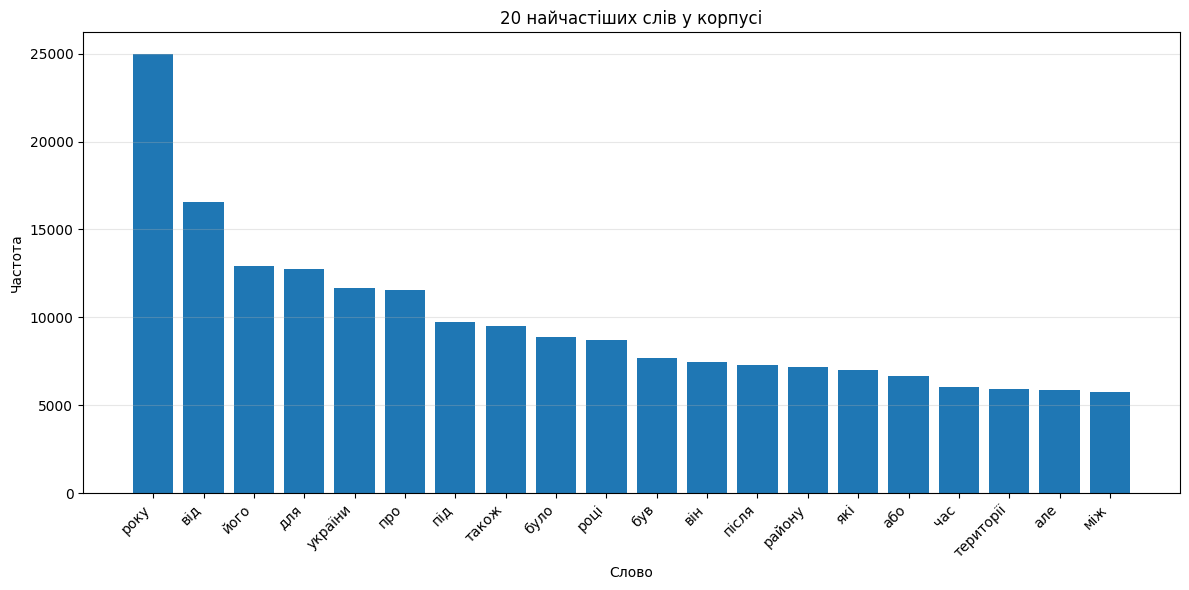

In [10]:
import matplotlib.pyplot as plt

words = [w for w, _ in top20]
counts = [c for _, c in top20]

plt.figure(figsize=(12, 6))
plt.bar(words, counts)
plt.xticks(rotation=45, ha="right")
plt.title("20 найчастіших слів у корпусі")
plt.xlabel("Слово")
plt.ylabel("Частота")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Висновок

Змінна `sentences` — це список списків слів, готовий до `gensim.models.Word2Vec(sentences=sentences, ...)`.

Серед найчастіших слів, швидше за все, будуть службові (`що`, `для`, `його`, `від`, `був`, `року`, `також`) — це нормально для Вікіпедії, бо стоп-слів ми не прибирали (для Word2Vec це не обов'язково, а іноді навіть корисно).